# GYRE to TDECalculator handoff

This notebook prepares clean GYRE HDF5 output for the collaborator's
unmodified `TDECalculator.py`.  It is an interface adapter, not a second
tidal-disruption implementation.  The calculator assumes adiabatic,
nonrotating quadrupole (`l=2`) modes, reads dimensionless `summary['omega']`,
and loads a legacy `M-gamma.txt` table relative to its own project directory.

Fresh execution is safe in a bare clone: absent GYRE results or absent TDE
project files are reported and the corresponding work is skipped.

## Contract and scientific limits

The bridge selects only `l=2` rows, requires one `n_pg=0` f mode, rejects
duplicate radial orders, validates the fields and common radial grid required
by the calculator, then stages legacy filenames `detail.l2.n±N.h5`.  It never
changes the GYRE source directory and will not overwrite a staging directory.
The external calculator expects `M_star` and `M_r` in g, `R_star` in cm,
`rho` in g cm^-3, and dimensionless `x=r/R_star`.

Passing this file contract is **not** a validation of the TDE model.  The
collaborator's `M-gamma.txt` is a mass-only calibration tabulated for MAMS
models; it may not apply to an RGB structure even if its HDF5 files stage
successfully.  Confirm or recompute the gamma/criterion with the collaborator
before interpreting RGB results.

The staging manifest records only input handoff provenance. It is not amended
with external calculation results, which remain the caller's responsibility to
save and document.

Dense RGB mixed-mode spectra can also make the external calculation expensive:
its time/mode work is roughly O(`N² × n_modes`) and it allocates arrays over
time, modes, and radial grid.  Use the optional radial-order limits only as
explicit exploratory subsets, then demonstrate convergence both with the
`l=2` GYRE scan and with the calculator's `N` time samples.

In [1]:
from pathlib import Path
import sys
import tempfile

def locate_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        marker = candidate / "scripts" / "run_gyre" / "pipeline" / "tde_bridge.py"
        if marker.is_file():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the cloned repository.")

REPO_ROOT = locate_repo_root(Path.cwd().resolve())
PIPELINE_DIR = REPO_ROOT / "scripts" / "run_gyre" / "pipeline"
if str(PIPELINE_DIR) not in sys.path:
    sys.path.insert(0, str(PIPELINE_DIR))

from tde_bridge import (
    inspect_gyre_run,
    plot_quadrupole_spectrum,
    prepare_tde_directory,
    preflight_tde_project,
    run_tde_calculator,
)


## Editable parameters

In [2]:
# Paths may be repository-relative or absolute. These defaults intentionally
# name no personal machine or collaborator checkout.
GYRE_RUN_DIR = Path("results/run_gyre/rgb_clean/rgb_5m_z0p0142_40r/nonradial")
TDE_ROOT = Path("TDECalculator")

# Leave None to stage in a TemporaryDirectory that this notebook removes at the end.
# Set a new, non-existing path to keep a manifest-backed compatibility directory.
PERSISTENT_OUTPUT_DIR = "results/tde_staging/rgb_5m_z0p0142_logR1p6"
TRANSFER_MODE = "copy"  # "copy" is portable; "hardlink" and "symlink" retain source dependence.

# Optional inclusive, explicitly recorded exploratory subset. Keep None for all l=2 modes.
N_PG_MIN = None
N_PG_MAX = None

# The external calculator is opt-in because it can be costly for dense spectra.
MBH = 1.0e6  # solar masses
Rp = 50.0    # GM_BH units
N = 10000     # orbit time samples; establish convergence before production use
RUN_TDE = True


## Read-only GYRE preflight

In [3]:
def resolve_from_repo(path: Path) -> Path:
    return path.expanduser().resolve() if path.is_absolute() else (REPO_ROOT / path).resolve()

SOURCE_DIR = resolve_from_repo(GYRE_RUN_DIR)
inspection = None
if not SOURCE_DIR.is_dir():
    print(f"No GYRE run directory yet: {SOURCE_DIR}")
    print("Run GYRE first, then set GYRE_RUN_DIR to its output directory.")
else:
    try:
        inspection = inspect_gyre_run(SOURCE_DIR, n_pg_min=N_PG_MIN, n_pg_max=N_PG_MAX)
        print(f"Validated {len(inspection.modes)} selected l=2 modes from {inspection.summary_path}")
        print(f"n_pg handoff: {list(inspection.selected_n_pg)}")
        print("TDE uses dimensionless omega; summary display-frequency units are not used.")
    except (OSError, ValueError) as exc:
        print(f"GYRE preflight did not pass: {exc}")


Validated 485 selected l=2 modes from /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/rgb_clean/rgb_5m_z0p0142_40r/nonradial/summary.h5
n_pg handoff: [-424, -423, -422, -421, -420, -419, -418, -417, -416, -415, -414, -413, -412, -411, -410, -409, -408, -407, -406, -405, -404, -403, -402, -401, -400, -399, -398, -397, -396, -395, -394, -393, -392, -391, -390, -389, -388, -387, -386, -385, -384, -383, -382, -381, -380, -379, -378, -377, -376, -375, -374, -373, -372, -371, -370, -369, -368, -367, -366, -365, -364, -363, -362, -361, -360, -359, -358, -357, -356, -355, -354, -353, -352, -351, -350, -349, -348, -347, -346, -345, -344, -343, -342, -341, -340, -339, -338, -337, -336, -335, -334, -333, -332, -331, -330, -329, -328, -327, -326, -325, -324, -323, -322, -321, -320, -319, -318, -317, -316, -315, -314, -313, -312, -311, -310, -309, -308, -307, -306, -305, -304, -303, -302, -301, -300, -299, -298, -297, -296, -295, -294, -293, -292, -291, -290, -289, -288, -287, -2

## Mode handoff diagnostic

Plotted 485 modes; masked non-finite modes: 0.


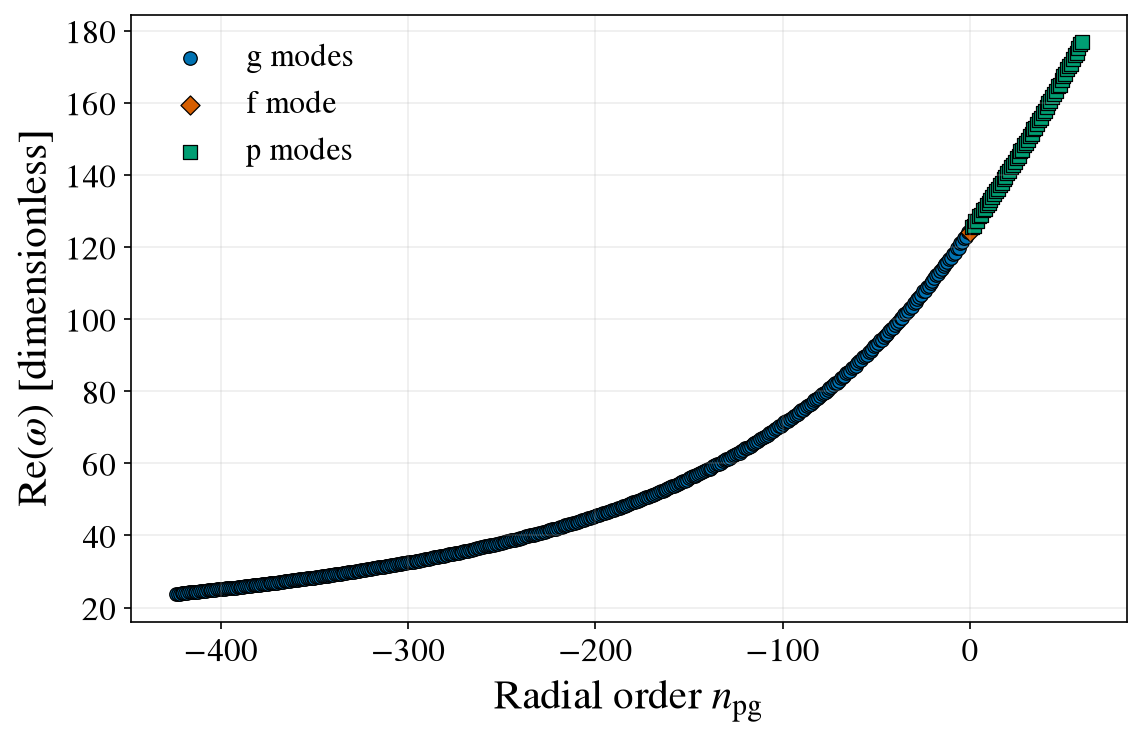

In [4]:
if inspection is None:
    print("No validated quadrupole spectrum to plot.")
else:
    fig, ax, spectrum_report = plot_quadrupole_spectrum(inspection)
    print(
        f"Plotted {spectrum_report.plotted_modes} modes; "
        f"masked non-finite modes: {spectrum_report.masked_nonfinite_modes}."
    )


## TDE project preflight

In [5]:
PROJECT_ROOT = resolve_from_repo(TDE_ROOT)
tde_project = None
if not PROJECT_ROOT.is_dir():
    print(f"No TDE project directory yet: {PROJECT_ROOT}")
    print("Set TDE_ROOT to a collaborator clone containing TDECalculator.py and M-gamma.txt.")
else:
    try:
        tde_project = preflight_tde_project(PROJECT_ROOT)
        print(f"TDECalculator module: {tde_project.calculator_path}")
        print(f"Relative gamma table: {tde_project.gamma_table_path}")
        print(f"M-gamma calibration domain: {tde_project.gamma_mass_domain_solar} M_sun")
        print(f"TDECalculator SHA-256: {tde_project.calculator_sha256}")
        print(f"M-gamma SHA-256: {tde_project.gamma_table_sha256}")
    except (OSError, ValueError) as exc:
        print(f"TDE project preflight did not pass: {exc}")


TDECalculator module: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/TDECalculator/TDECalculator.py
Relative gamma table: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/TDECalculator/M-gamma.txt
M-gamma calibration domain: (0.15, 8.0) M_sun
TDECalculator SHA-256: 77a48c358fec144d9720bb7a7e54c80d8e59715ad38c6a3e8ee6e7e1dd058720
M-gamma SHA-256: d5b05f279ecc2795391aa992b3742799f11070cae0cba1764d96c11b33ef2c2a


## Stage a fresh legacy-compatible directory

In [6]:
prepared = None
_temporary_stage = None
if inspection is None:
    print("Skipping staging until the GYRE preflight succeeds.")
else:
    if PERSISTENT_OUTPUT_DIR is None:
        _temporary_stage = tempfile.TemporaryDirectory(prefix="gyre-tde-")
        stage_dir = Path(_temporary_stage.name) / "star"
        print(f"Using temporary stage: {stage_dir}")
    else:
        stage_dir = resolve_from_repo(Path(PERSISTENT_OUTPUT_DIR))
        print(f"Creating persistent stage (must not already exist): {stage_dir}")
    try:
        prepared = prepare_tde_directory(
            SOURCE_DIR,
            stage_dir,
            n_pg_min=N_PG_MIN,
            n_pg_max=N_PG_MAX,
            transfer_mode=TRANSFER_MODE,
        )
        print(f"Prepared {prepared.directory}")
        print(f"Manifest: {prepared.manifest_path}")
    except (OSError, ValueError) as exc:
        if _temporary_stage is not None:
            _temporary_stage.cleanup()
            _temporary_stage = None
        print(f"Staging did not complete: {exc}")


Creating persistent stage (must not already exist): /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/tde_staging/rgb_5m_z0p0142_logR1p6
Prepared /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/tde_staging/rgb_5m_z0p0142_logR1p6
Manifest: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/tde_staging/rgb_5m_z0p0142_logR1p6/tde_bridge_manifest.json


## Optional external TDE calculation

In [7]:
calculator_result = None
if not RUN_TDE:
    print("TDE execution is disabled. Set RUN_TDE=True only after calibration and convergence review.")
elif prepared is None:
    print("Skipping TDE execution because no staged input directory is available.")
elif tde_project is None:
    print("Skipping TDE execution because the TDE project preflight did not pass.")
else:
    # The bridge changes cwd to TDE_ROOT only while constructing the collaborator
    # calculator, so its legacy relative M-gamma.txt lookup works and cwd is restored.
    calculator_result = run_tde_calculator(
        prepared.directory, tde_project.root, MBH=MBH, Rp=Rp, N=N
    )
    print(f"Constructed external TDECalculator for {prepared.directory}")


Constructed external TDECalculator for /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/tde_staging/rgb_5m_z0p0142_logR1p6


In [8]:
# Default staging is deliberately ephemeral. Persistent output is retained only
# when PERSISTENT_OUTPUT_DIR was explicitly set above.
if _temporary_stage is not None:
    _temporary_stage.cleanup()
    _temporary_stage = None
    print("Removed the temporary compatibility directory.")
